# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 5: Ứng dụng nhận dạng chữ số viết tay MNIST (Mục 7 trang 27 - 31)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split
from PIL import Image, ImageOps

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("Dataset", os.path.basename(rel_path)),
        os.path.join("..", "Dataset", os.path.basename(rel_path)),
        os.path.join("..", "..", "Dataset", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file: {rel_path}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


### Bước 1 & 2: Tải dữ liệu MNIST và biểu diễn 4 mẫu dữ liệu huấn luyện
- Tải tập dữ liệu chữ số viết tay Digits từ scikit-learn (`datasets.load_digits()`).
- Hiển thị 4 mẫu hình ảnh đầu tiên tương ứng với các chữ số 0, 1, 2, 3.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Tổng số lượng mẫu ảnh chữ số: 1797
Kích thước mỗi ảnh: (8, 8)


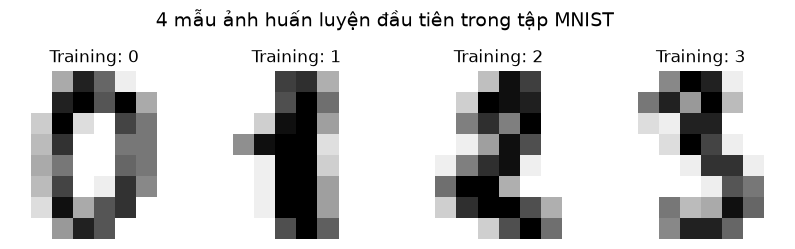

In [2]:
# Bước 1 & 2: Tải dữ liệu và biểu diễn 4 mẫu đầu tiên
digits = datasets.load_digits()

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Tổng số lượng mẫu ảnh chữ số: {len(digits.images)}")
print(f"Kích thước mỗi ảnh: {digits.images[0].shape}")

# Biểu diễn 4 mẫu dữ liệu huấn luyện tương ứng với 4 lớp 0, 1, 2, 3
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f'Training: {label}')
plt.suptitle("4 mẫu ảnh huấn luyện đầu tiên trong tập MNIST", fontsize=14)
plt.show()

### Bước 3 & 4: Chuyển đổi ma trận ảnh 8x8 thành vector 1x64 và xây dựng cây ID3
- Duỗi ma trận 8x8 thành vector đặc trưng 64 chiều (`digits.images.reshape((n_samples, -1))`).
- Chia tập dữ liệu 80% huấn luyện và 20% kiểm thử (`test_size=0.2, shuffle=False`).
- Huấn luyện mô hình cây quyết định ID3 với tiêu chí entropy (`DecisionTreeClassifier(criterion="entropy", random_state=33)`).

In [3]:
# Bước 3 & 4: Chuyển đổi dữ liệu và huấn luyện cây ID3
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# Chia dữ liệu: 80% huấn luyện, 20% kiểm thử
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=False
)

# Xây dựng và huấn luyện mô hình cây quyết định ID3
classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)
classifier.fit(X_train, y_train)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước dữ liệu sau khi duỗi: {data.shape}")
print(f"Kích thước tập huấn luyện X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Kích thước tập kiểm thử X_test: {X_test.shape}, y_test: {y_test.shape}")
print("Huấn luyện mô hình cây quyết định ID3 thành công.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước dữ liệu sau khi duỗi: (1797, 64)
Kích thước tập huấn luyện X_train: (1437, 64), y_train: (1437,)
Kích thước tập kiểm thử X_test: (360, 64), y_test: (360,)
Huấn luyện mô hình cây quyết định ID3 thành công.
